# Rules and reproduction, 1990-2001

The years where S&P 500 membership is observed. Section 3 also writes the company-month eligibility panel that `02_prediction.ipynb` reads, so this notebook runs first.

In [1]:
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import maqi_hackathon_2 as h
from maqi_hackathon_2 import data

FIGURES = Path.cwd().parent / "figures"
FIGURES.mkdir(exist_ok=True)
INDEX_ID = "000003"

data.build()
frame = data.load(index=INDEX_ID)
truth = h.composition.truth(INDEX_ID, end="2001-12-31")
published = data.index_returns(INDEX_ID)
print(f"{truth['month'].nunique()} month ends, {truth['security'].nunique()} securities ever members")

144 month ends, 799 securities ever members


## Two traps

Point in time: `data.load()` attaches to each month end the last quarter whose `available_from` is on or before it, a median 43 days after its `period_end` (90th percentile 88), and every weight below is a cap from before the return it weights. Monthly `market_cap` covers 0.1% of panel rows in 1990 and 91% in 2001 and is essentially missing before 1998, so rank statistics start at the first month with 80% coverage, 1998-04.

In [2]:
MIN_CAP_COVERAGE = 0.80

lag = (pl.scan_parquet(data.path("fundamentals_quarterly"))
       .select((pl.col("available_from").cast(pl.Date) - pl.col("period_end").cast(pl.Date)).dt.total_days().alias("days"))
       .collect()["days"])
cap_cov = (frame.filter(pl.col("month_end").is_between(pl.date(1990, 1, 1), pl.date(2001, 12, 31)))
           .group_by("month_end")
           .agg(rows=(pl.col("market_cap") > 0).fill_null(False).mean(),
                members=(pl.col("market_cap_prev") > 0).fill_null(False).filter(pl.col("member_prev")).mean())
           .sort("month_end").collect())
CAP_FIRST_MONTH = cap_cov.filter(pl.col("rows") >= MIN_CAP_COVERAGE)["month_end"].min()

print(f"filing lag: median {lag.median():.0f} days, 90th percentile {lag.quantile(0.9):.0f} days")
print(cap_cov.group_by(pl.col("month_end").dt.year().alias("year")).agg(pl.col("rows", "members").mean().round(3)).sort("year"))
print("first month with cap coverage >= 0.80:", CAP_FIRST_MONTH)

filing lag: median 43 days, 90th percentile 88 days
shape: (12, 3)
┌──────┬───────┬─────────┐
│ year ┆ rows  ┆ members │
│ ---  ┆ ---   ┆ ---     │
│ i32  ┆ f64   ┆ f64     │
╞══════╪═══════╪═════════╡
│ 1990 ┆ 0.001 ┆ 0.0     │
│ 1991 ┆ 0.001 ┆ 0.0     │
│ 1992 ┆ 0.001 ┆ 0.0     │
│ 1993 ┆ 0.001 ┆ 0.0     │
│ 1994 ┆ 0.001 ┆ 0.002   │
│ …    ┆ …     ┆ …       │
│ 1997 ┆ 0.001 ┆ 0.002   │
│ 1998 ┆ 0.668 ┆ 0.667   │
│ 1999 ┆ 0.881 ┆ 1.0     │
│ 2000 ┆ 0.89  ┆ 1.0     │
│ 2001 ┆ 0.911 ┆ 1.0     │
└──────┴───────┴─────────┘
first month with cap coverage >= 0.80: 1998-04-30


Survivorship: the pool that earns month t's return is the membership at the end of t-1, read from the spells, so names that leave or stop trading earn their last month. Of the 500 members at the end of 1990-01, 230 are out of the index by 2001-12 and 162 stopped trading before 2002.

In [3]:
last_month = (pl.scan_parquet(data.path("prices_monthly")).group_by("security").agg(pl.col("month_end").max())
              .collect().to_pandas().set_index("security")["month_end"])
first_members = set(truth.loc[truth["month"] == truth["month"].min(), "security"])
last_members = set(truth.loc[truth["month"] == truth["month"].max(), "security"])
stopped = pd.to_datetime(last_month.reindex(sorted(first_members))) < pd.Timestamp("2002-01-01")
print(f"{len(first_members)} members at 1990-01, {len(first_members - last_members)} out of the index by 2001-12, "
      f"{int(stopped.sum())} stopped trading before 2002")

500 members at 1990-01, 230 out of the index by 2001-12, 162 stopped trading before 2002


## Rules

How many names change, and when: 9 to 53 additions a year over 1990-2001 (12 in 1990, 53 in 2000), deletions within one of them, at least one addition in 76% of months, an index size between 498 and 500. By calendar month, additions range from 9 (February) to 38 (December) over the twelve years.

In [4]:
sets = truth.groupby("month")["security"].apply(set)
changes = pd.DataFrame({"additions": [len(b - a) for a, b in zip(sets.iloc[:-1], sets.iloc[1:])],
                        "deletions": [len(a - b) for a, b in zip(sets.iloc[:-1], sets.iloc[1:])],
                        "size": sets.iloc[1:].map(len).to_numpy()},
                       index=sets.index[1:])
print(changes.groupby(changes.index.year)[["additions", "deletions"]].sum().T)
print("additions by calendar month:", changes.groupby(changes.index.month)["additions"].sum().to_dict())
print(f"size {changes['size'].min()} to {changes['size'].max()}, "
      f"{(changes['additions'] > 0).mean():.0%} of months with an addition")

month      1990  1991  1992  1993  1994  1995  1996  1997  1998  1999  2000  \
additions    12    10     9    13    18    27    20    30    37    43    53   
deletions    12    10     9    13    18    28    19    30    37    43    54   

month      2001  
additions    30  
deletions    29  
additions by calendar month: {1: 28, 2: 9, 3: 15, 4: 23, 5: 20, 6: 27, 7: 33, 8: 28, 9: 20, 10: 36, 11: 25, 12: 38}
size 498 to 500, 76% of months with an addition


The index is not the 500 largest names, and members are not held to the entry bar: on 1998-04 to 2001-12, additions enter at a median cap rank of 575 with 60.5% outside the top 500, 54.1% of members rank outside it in a given month, and members that leave while still priced sit at a median rank of 912. Ranks are over every priced USD primary issue of the month, so rank 500 is not the 500th US common stock. Where it fails: 28.4% of these deletions were still in the top 500 when they left.

In [5]:
research = (frame
            .filter(pl.col("month_end").is_between(pl.date(1990, 1, 1), pl.date(2001, 12, 31)))
            .select("month_end", "security", "market_cap", "member", "member_prev")
            .unique(["month_end", "security"])
            .with_columns(market_cap_rank=pl.col("market_cap").rank(method="ordinal", descending=True).over("month_end"),
                          addition=pl.col("member") & ~pl.col("member_prev"),
                          deletion=~pl.col("member") & pl.col("member_prev"))
            .filter(pl.col("month_end") >= CAP_FIRST_MONTH)
            .select("member", "addition", "deletion", "market_cap_rank")
            .collect())
groups = {"additions": research.filter(pl.col("addition")), "deletions": research.filter(pl.col("deletion")),
          "members": research.filter(pl.col("member")), "non-members": research.filter(~pl.col("member"))}
print(pd.DataFrame({name: {"n": g["market_cap_rank"].drop_nulls().len(),
                           "median rank": g["market_cap_rank"].median(),
                           "share outside top 500": (g["market_cap_rank"].drop_nulls() > 500).mean(),
                           "share outside top 300": (g["market_cap_rank"].drop_nulls() > 300).mean()}
                    for name, g in groups.items()}).round(3))

                       additions  deletions    members  non-members
n                        157.000    134.000  22473.000   468933.000
median rank              575.000    912.000    541.000     5710.000
share outside top 500      0.605      0.716      0.541        0.974
share outside top 300      0.873      0.866      0.756        0.983


The methodology's entry screens, rebuilt point in time per company (caps summed over share classes): cap above the level where the largest companies reach 85% of the month's total, four positive quarters of income before extraordinary items as first published, and 12-month dollar volume above 0.30 of cap. At the month of entry, of 299 company additions (52% in the base universe), 10.7% pass the size screen, 33.4% the profitability screen, 43.5% the liquidity screen and 2.7% all three. Where they fail: about 1 non-member passes all three each month, for 2.1 additions; most of this is the missing monthly caps before 1998, which fail the size and liquidity screens, so as rebuilt here the screens neither bound nor pick the candidates.

In [6]:
LARGE_CAP_CUM_SHARE = 0.85
HISTORICAL_TURNOVER_THRESHOLD = 0.30
CAP_WINDOW = 1

cols = ["month_end", "security", "company_id", "market_cap", "close", "volume", "member", "member_prev",
        "income_before_extraordinary_items", "period_end", "available_from", "gics_sector"]
work = (frame.filter(pl.col("month_end") >= pl.date(1989, 6, 30)).select(cols)
        .unique(["month_end", "security"]).collect().to_pandas())
work["month_end"] = pd.to_datetime(work["month_end"]).dt.to_period("M").dt.to_timestamp("M")
work[["period_end", "available_from"]] = work[["period_end", "available_from"]].apply(pd.to_datetime)
work = work.loc[work["company_id"].notna() & work["security"].notna() & work["market_cap"].gt(0) & work["close"].gt(0)]

company_cap = work.groupby(["month_end", "company_id"])["market_cap"].sum().rename("company_market_cap").reset_index()
panel = (work.loc[work.groupby(["month_end", "company_id"])["market_cap"].idxmax()]
         .merge(company_cap, on=["month_end", "company_id"])
         .sort_values(["company_id", "month_end"]).reset_index(drop=True))
by_company = panel.groupby("company_id")
panel["company_cap_3m"] = by_company["company_market_cap"].transform(lambda s: s.rolling(CAP_WINDOW, min_periods=1).mean())
panel["turnover_12m"] = ((panel["close"] * panel["volume"]).groupby(panel["company_id"])
                         .transform(lambda s: s.rolling(12, min_periods=6).sum()) / panel["company_cap_3m"])

quarters = (panel[["company_id", "period_end", "available_from", "income_before_extraordinary_items"]]
            .dropna(subset=["period_end", "income_before_extraordinary_items"])
            .sort_values(["company_id", "period_end", "available_from"])
            .drop_duplicates(["company_id", "period_end"], keep="first"))
earn = quarters.groupby("company_id")["income_before_extraordinary_items"]
quarters["profit_4q_positive"] = (earn.transform(lambda s: s.rolling(4, min_periods=1).count()).ge(4)
                                  & earn.transform(lambda s: s.rolling(4, min_periods=4).min()).gt(0))
panel = panel.merge(quarters[["company_id", "period_end", "profit_4q_positive"]], on=["company_id", "period_end"], how="left")
panel["profit_4q_positive"] = panel["profit_4q_positive"].eq(True)

panel["active_proxy"] = panel["close"].gt(0) & panel["company_market_cap"].gt(0)
panel["base_universe"] = panel["active_proxy"] & panel["period_end"].notna() & panel["available_from"].notna()
base = (panel.loc[panel["base_universe"] & panel["company_cap_3m"].notna()]
        .sort_values(["month_end", "company_cap_3m"], ascending=[True, False]))
base["cum_market_share"] = (base.groupby("month_end")["company_cap_3m"].cumsum()
                            / base.groupby("month_end")["company_cap_3m"].transform("sum"))
base["cap_rank"] = base.groupby("month_end")["company_cap_3m"].rank(method="first", ascending=False)
thresholds = (base.loc[base["cum_market_share"] >= LARGE_CAP_CUM_SHARE].groupby("month_end")["company_cap_3m"].first()
              .rename("large_cap_threshold").reset_index())
panel = (panel.merge(thresholds, on="month_end", how="left")
         .merge(base[["month_end", "company_id", "cap_rank"]], on=["month_end", "company_id"], how="left"))
panel["large_cap_proxy"] = panel["company_cap_3m"] >= panel["large_cap_threshold"]
panel["eligible_2001_proxy"] = (panel["base_universe"] & panel["large_cap_proxy"] & panel["profit_4q_positive"]
                                & panel["turnover_12m"].ge(HISTORICAL_TURNOVER_THRESHOLD))

panel[["month_end", "company_id", "security", "member", "gics_sector", "company_cap_3m", "turnover_12m", "cap_rank",
       "active_proxy", "base_universe", "large_cap_proxy", "profit_4q_positive", "eligible_2001_proxy"]].to_parquet(
    data.store() / "turing_eligibility_panel.parquet")
print(f"{len(panel):,} company-months, {panel['month_end'].min():%Y-%m} to {panel['month_end'].max():%Y-%m}")

4,319,006 company-months, 1990-01 to 2026-06


In [7]:
additions = (frame.filter(pl.col("member") & ~pl.col("member_prev")
                          & pl.col("month_end").is_between(pl.date(1990, 2, 1), pl.date(2001, 12, 31)))
             .select("month_end", "company_id").unique().collect().to_pandas())
additions["month_end"] = pd.to_datetime(additions["month_end"]).dt.to_period("M").dt.to_timestamp("M")
at_entry = additions.merge(panel, on=["month_end", "company_id"], how="left")
screens = ["large_cap_proxy", "profit_4q_positive", "eligible_2001_proxy"]
print(f"{len(at_entry)} company additions, {at_entry['base_universe'].eq(True).mean():.0%} in the base universe")
print(at_entry[screens].eq(True).mean().round(3).to_dict(),
      "liquidity:", round(at_entry["turnover_12m"].ge(HISTORICAL_TURNOVER_THRESHOLD).mean(), 3))
window = panel.loc[panel["month_end"].between("1990-02-01", "2001-12-31")]
eligible_outsiders = window.loc[~window["member"].eq(True)].groupby("month_end")["eligible_2001_proxy"].sum()
print(f"eligible non-members per month: {eligible_outsiders.mean():.0f}; additions per month: {changes['additions'].mean():.1f}")

299 company additions, 52% in the base universe
{'large_cap_proxy': 0.107, 'profit_4q_positive': 0.334, 'eligible_2001_proxy': 0.027} liquidity: 0.435
eligible non-members per month: 1; additions per month: 2.1


Exits: of the 302 deletions of 1990-2001, 59% stop trading within three months of leaving and 34% still trade a year later; a size rule can only anticipate the second kind.

In [8]:
deletions = pd.DataFrame([(month, s) for a, b, month in zip(sets.iloc[:-1], sets.iloc[1:], sets.index[1:]) for s in a - b],
                         columns=["month", "security"])
deletions["last_month"] = pd.to_datetime(deletions["security"].map(last_month))
print(f"{len(deletions)} deletions; stop trading within 3 months: "
      f"{(deletions['last_month'] <= deletions['month'] + pd.offsets.MonthEnd(2)).mean():.0%}; "
      f"still trading 12 months later: {(deletions['last_month'] > deletions['month'] + pd.offsets.MonthEnd(12)).mean():.0%}")

302 deletions; stop trading within 3 months: 59%; still trading 12 months later: 34%


## Reproduction

The composition is the month-end membership from the spells; the index on it uses total returns, dead names included, and cap weights from the previous month end (monthly build) or from the previous trading day with exact daily membership (daily build, `prices_daily` for member securities only). Over 1990-02 to 2001-12 the daily build scores correlation 0.9992, slope 1.0093 and tracking error 57.5 bp, equal weights on the same pool 0.9134, 0.8622 and 623.7 bp; the brief has 0.9995, 1.0055, 46 bp and 0.9135, 0.8627, 623 bp. The monthly build scores correlation 0.5163 on the 93 months it has weights for, because monthly caps are missing before 1998.

In [9]:
def score_table(series):
    out = pd.DataFrame({name: h.score(s, published) for name, s in series.items()}).T
    out["tracking_error_bp"] = out.pop("tracking_error") * 1e4
    out["months"] = [h.monthly(s).dropna().index.intersection(published.index).size for s in series.values()]
    return out.round(4)


pool = (frame.filter(pl.col("member_prev") & pl.col("return_total_monthly").is_not_null()
                     & pl.col("month_end").is_between(pl.date(1990, 2, 1), pl.date(2001, 12, 31)))
        .select("month_end", "security", "market_cap_prev", "return_total_monthly")
        .unique(["month_end", "security"]).collect())
cap_weighted = (pool.filter(pl.col("market_cap_prev") > 0).group_by("month_end")
                .agg((pl.col("market_cap_prev") * pl.col("return_total_monthly")).sum() / pl.col("market_cap_prev").sum())
                .sort("month_end").to_pandas().set_index("month_end").iloc[:, 0])
equal_weighted = (pool.group_by("month_end").agg(pl.col("return_total_monthly").mean())
                  .sort("month_end").to_pandas().set_index("month_end").iloc[:, 0])
print(score_table({"monthly, previous month-end caps": cap_weighted, "equal weights": equal_weighted}))

                                  correlation   slope  tracking_error_bp  \
monthly, previous month-end caps       0.5163  0.2960          2298.6540   
equal weights                          0.9134  0.8622           623.7212   

                                  months  
monthly, previous month-end caps      93  
equal weights                        143  


In [10]:
RETURN_COLUMNS = ["return_total_daily", "return_total_daily_corrected", "return_total_daily_raw"]

spells = (pl.scan_parquet(data.path("index_membership")).filter(pl.col("index_id") == INDEX_ID)
          .select("security", "member_from", "member_through"))
daily = (data.scan("prices_daily")
         .filter(pl.col("date").is_between(date(1989, 12, 1), date(2001, 12, 31)))
         .join(spells.select("security").unique(), on="security", how="semi")
         .select("security", "date", "market_cap", "close", "shares_outstanding", *RETURN_COLUMNS)
         .sort("security", "date")
         .with_columns(market_cap_prev_daily_raw=pl.col("market_cap").shift().over("security"),
                       close_prev_daily=pl.col("close").shift().over("security"),
                       shares_prev_daily=pl.col("shares_outstanding").shift().over("security"),
                       ym=(pl.col("date").dt.year() * 100 + pl.col("date").dt.month()).cast(pl.Int64))
         .with_columns(fallback=pl.when((pl.col("close_prev_daily") > 0) & (pl.col("shares_prev_daily") > 0))
                       .then(pl.col("close_prev_daily") * pl.col("shares_prev_daily")))
         .with_columns(market_cap_prev_daily=pl.when(pl.col("market_cap_prev_daily_raw") > 0)
                       .then(pl.col("market_cap_prev_daily_raw")).otherwise(pl.col("fallback")),
                       used_market_cap_fallback=(pl.col("market_cap_prev_daily_raw").is_null()
                                                 | (pl.col("market_cap_prev_daily_raw") <= 0))
                       & pl.col("fallback").is_not_null())
         .collect())
print(f"{daily.height:,} security-days, {daily['security'].n_unique():,} securities")

2,035,149 security-days, 798 securities


daily return field: return_total_daily
                                            correlation   slope  \
daily, exact membership                          0.9992  1.0093   
daily, previous month-end composition held       0.9992  1.0099   
monthly, previous month-end caps                 0.5163  0.2960   
equal weights                                    0.9134  0.8622   
brief: right construction                        0.9995  1.0055   
brief: equal weights                             0.9135  0.8627   

                                            tracking_error_bp  months  
daily, exact membership                               57.4867   143.0  
daily, previous month-end composition held            57.6155   143.0  
monthly, previous month-end caps                    2298.6540    93.0  
equal weights                                        623.7212   143.0  
brief: right construction                             46.0000     NaN  
brief: equal weights                                 623.00

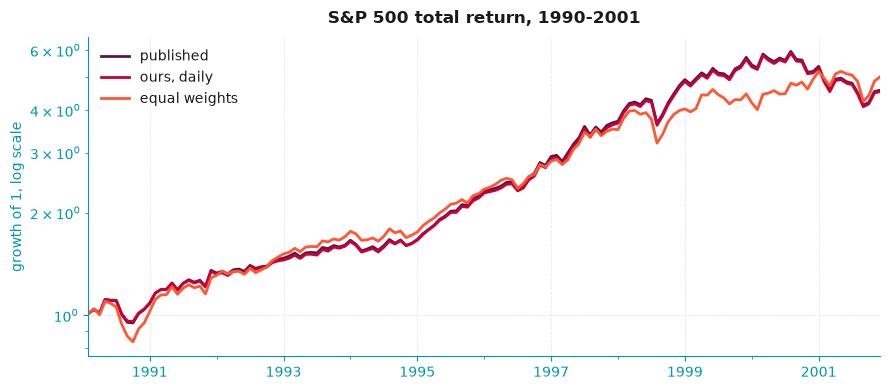

In [11]:
def build_daily_index(rows, return_col):
    return (rows.filter(pl.col(return_col).is_not_null() & (pl.col("market_cap_prev_daily") > 0))
            .group_by("date")
            .agg(((pl.col("market_cap_prev_daily") * pl.col(return_col)).sum()
                  / pl.col("market_cap_prev_daily").sum()).alias("return"),
                 pl.col("security").n_unique().alias("n_members"))
            .sort("date").collect().to_pandas())


def daily_to_monthly(daily_index, name):
    month = pd.to_datetime(daily_index["date"]).dt.to_period("M")
    return (1 + daily_index["return"]).groupby(month).prod().sub(1).rename(name)


exact_rows = (daily.lazy().join(spells, on="security")
              .filter((pl.col("member_from") <= pl.col("date"))
                      & (pl.col("member_through").is_null() | (pl.col("member_through") >= pl.col("date")))))
truth_by_period = truth.groupby(truth["month"].dt.to_period("M"))["security"].apply(set)
held = pl.DataFrame([{"ym": (p + 1).year * 100 + (p + 1).month, "security": s}
                     for p, members in truth_by_period.items() for s in members],
                    schema={"ym": pl.Int64, "security": pl.String})
held_rows = daily.lazy().join(held.lazy(), on=["ym", "security"])

by_return_col = {c: daily_to_monthly(build_daily_index(exact_rows, c), c) for c in RETURN_COLUMNS}
DAILY_RETURN_COL = pd.Series({c: h.score(s, published)["tracking_error"] for c, s in by_return_col.items()}).idxmin()
reproduction = {
    "daily, exact membership": by_return_col[DAILY_RETURN_COL],
    "daily, previous month-end composition held": daily_to_monthly(build_daily_index(held_rows, DAILY_RETURN_COL), "held"),
    "monthly, previous month-end caps": cap_weighted,
    "equal weights": equal_weighted,
}
table = score_table(reproduction)
table.loc["brief: right construction"] = [0.9995, 1.0055, 46, np.nan]
table.loc["brief: equal weights"] = [0.9135, 0.8627, 623, np.nan]
print("daily return field:", DAILY_RETURN_COL)
print(table)

growth = pd.concat({"published": published, "ours, daily": reproduction["daily, exact membership"],
                    "equal weights": h.monthly(equal_weighted)}, axis=1).dropna()
ax = (1 + growth).cumprod().plot(logy=True, figsize=(9, 4), title="S&P 500 total return, 1990-2001")
ax.set_ylabel("growth of 1, log scale")
plt.tight_layout()
plt.savefig(FIGURES / "reproduction_1990_2001.png", dpi=150)

## Residual

What the 57.5 bp of the daily build are made of. By year it ranges from 13 bp (2001) to 103 bp (1993) (figure); by cause, `return_total_daily` and `return_total_daily_raw` both give 57.5 bp and `return_total_daily_corrected` 36,865 bp, unusable as is; intra-month timing (exact membership against the previous month-end composition held over the month) is 7.6 bp; daily against monthly weights is 2,288 bp, the missing monthly caps before 1998, since the monthly build tracks within 23 to 35 bp a year from 1999. No member-day needed a cap rebuilt from close times shares and 3.5% have no weight.

                                  1990  1991  1992   1993    1994    1995  \
daily, exact membership           84.0  58.0  63.0  103.0    73.0    48.0   
monthly, previous month-end caps   NaN   NaN   NaN    NaN  2231.0  2580.0   

                                    1996    1997   1998  1999  2000  2001  
daily, exact membership             50.0    59.0   21.0  18.0  30.0  13.0  
monthly, previous month-end caps  3454.0  4269.0  823.0  26.0  35.0  23.0  
return field return_total_daily                           57.5
return field return_total_daily_corrected              36865.2
return field return_total_daily_raw                       57.5
timing: exact daily against previous month-end held        7.6
weights: daily against monthly build                    2287.9
dtype: float64
member-days 1,511,527: cap from close x shares 0.0%, no weight 3.5%


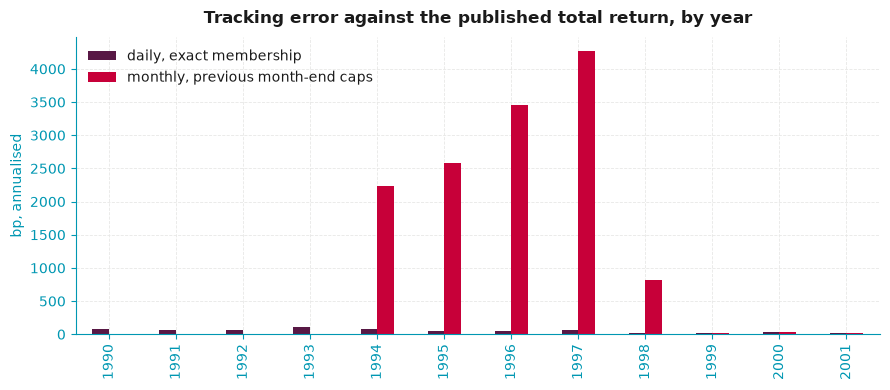

In [12]:
def te_bp(a, b):
    return (h.monthly(a) - h.monthly(b)).dropna().std() * np.sqrt(12) * 1e4


def te_by_year(s):
    diff = (h.monthly(s) - published).dropna()
    return diff.groupby(diff.index.year).std() * np.sqrt(12) * 1e4


exact = reproduction["daily, exact membership"]
by_year = pd.DataFrame({name: te_by_year(reproduction[name])
                        for name in ["daily, exact membership", "monthly, previous month-end caps"]}).round(0)
print(by_year.T)
ax = by_year.plot.bar(figsize=(9, 4), title="Tracking error against the published total return, by year")
ax.set_ylabel("bp, annualised")
plt.tight_layout()
plt.savefig(FIGURES / "residual_by_year.png", dpi=150)

causes = pd.Series({
    **{f"return field {c}": te_bp(s, published) for c, s in by_return_col.items()},
    "timing: exact daily against previous month-end held": te_bp(exact, reproduction["daily, previous month-end composition held"]),
    "weights: daily against monthly build": te_bp(exact, cap_weighted),
}).round(1)
coverage = exact_rows.select(pl.len().alias("member_days"),
                             pl.col("used_market_cap_fallback").sum().alias("fallback"),
                             (pl.col("market_cap_prev_daily").is_null() | (pl.col("market_cap_prev_daily") <= 0))
                             .sum().alias("no_weight")).collect()
print(causes)
print(f"member-days {coverage['member_days'][0]:,}: cap from close x shares {coverage['fallback'][0] / coverage['member_days'][0]:.1%}, "
      f"no weight {coverage['no_weight'][0] / coverage['member_days'][0]:.1%}")

## Parameters

| parameter | value | why | what else we tried |
|---|---|---|---|
| `MIN_CAP_COVERAGE` | 0.80 | a cap rank only means something when most names of the month carry a cap | none |
| `LARGE_CAP_CUM_SHARE` | 0.85 | the methodology puts the large-cap boundary where the largest companies reach about 85% of total cap; a share means the same in 1990 and 2026 | today's nominal floor ($22.7bn), anachronistic for the 1990s |
| `HISTORICAL_TURNOVER_THRESHOLD` | 0.30 | the liquidity screen of the period, approximated by 12-month dollar volume over cap from monthly data | 0.75 with 250k shares a day over six months (today's rule), coded but not applied before 2002 |
| profitability | four positive quarters, first published figures | the rule of the period; first publication avoids restated numbers | latest quarter and trailing four quarters positive (today's rule), coded but not applied |
| `CAP_WINDOW` | 1 month | the latest company cap, as in the version we ran; why the 3-month average was dropped is not recorded | 3-month average cap |
| weights | cap at the previous month end, or at the previous trading day | known before the return it weights | equal weights, kept as the control |
| `DAILY_RETURN_COL` | the field with the lowest tracking error | chosen on the target, so it is calibration; the residual shows all three | the other two fields |

## Takeaways

- The daily build on the observed composition scores correlation 0.9992, slope 1.0093 and tracking error 57.5 bp over 1990-2001; equal weights on the same names score slope 0.8622.
- Its residual: 13 to 103 bp by year, 7.6 bp from intra-month timing, 57.5 bp for two of the daily return fields and 36,865 bp for the third.
- Entry: median cap rank 575 at entry, and 54.1% of members rank outside the top 500 in a given month.
- Exits: 59% of deletions stop trading within three months, 34% still trade a year later.
- The entry screens pass 2.7% of additions and about 1 non-member a month, for 2.1 additions a month; monthly caps missing before 1998-04 drive most of this.